# Windowed Cointegration — do 50-day "pair bands" persist, or are they noise?

**The observation:** if you compute an all-pairs **cointegration matrix inside a
50-day window** and slide it through time, certain pairs / blocks ("bands") light
up, and the pattern seems to move from window to window.

**The danger:** 50 observations is *very* little to test cointegration on. With
~1,275 pairs, pure chance alone paints a lot of "cointegrated" cells. So before
believing any band we must ask: **how much of this exceeds the false-positive rate
of the test at n = 50?**

This notebook:

1. Measures the **small-sample false-positive rate** of the Engle–Granger test at
   n = 50 by Monte-Carlo (independent random walks) — the chance baseline.
2. Computes the **cointegration matrix in every 50-day window** (rolling, step 10;
   plus 15 clean non-overlapping blocks).
3. **Seriates** the instruments by cointegration *persistence* so the bands become
   visible as blocks, and tests which bands beat chance.
4. Tracks **instrument-level and market-wide** cointegration through time to
   characterise the moving pattern (regimes).
5. Checks whether the hand-picked **focus pairs** persist window-to-window.

## 0 · Setup

Same colourblind-safe palette as the main notebook, plus a **fast** cointegration
test tuned for short windows: `coint(..., autolag=None, maxlag=1)` is ~5x faster
than the AIC-search default and appropriate for 50-point series.

In [1]:
import time
from itertools import combinations

import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import coint
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster, dendrogram
from scipy.spatial.distance import squareform
from scipy.stats import binom
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

import warnings; warnings.filterwarnings("ignore")

CAT = ["#2a78d6", "#eb6834", "#008300", "#4a3aa7", "#eda100",
       "#1baf7a", "#e87ba4", "#e34948"]
BLUE, ORANGE, GREEN, RED = "#2a78d6", "#eb6834", "#008300", "#e34948"
GRID, MUTED, INK = "#e1e0d9", "#898781", "#0b0b0b"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f3ef", "#9ec5f4", BLUE, "#0d366b"])
SEQ_G = LinearSegmentedColormap.from_list("seqg", ["#f4f3ef", "#bfe3cf", "#1baf7a", "#0b5c3b"])
BIN = ListedColormap(["#f4f3ef", BLUE])

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID,
    "axes.titleweight": "bold", "figure.dpi": 110, "font.size": 9,
})

def fast_coint(y, x):
    '''Engle-Granger p-value, tuned for short windows.'''
    try:
        return coint(y, x, autolag=None, maxlag=1)[1]
    except Exception:
        return np.nan

print("Setup complete.")

Setup complete.


## 1 · Data and the window scheme

`W = 50`-day windows. We slide with `STEP = 10` for a smooth time view (**71
rolling windows**), and separately pull out the **15 non-overlapping blocks**
(days 0–50, 50–100, …) — these are statistically independent, which we need for
the persistence significance test.

In [2]:
prices = pd.read_csv("prices.txt", sep=r"\s+")
TICKERS = list(prices.columns)
N = len(TICKERS)
ndays = len(prices)
IDX = {t: i for i, t in enumerate(TICKERS)}

W, STEP = 50, 10
starts = list(range(0, ndays - W + 1, STEP))          # rolling window start days
centers = [s + W // 2 for s in starts]
noov_pos = [k for k, s in enumerate(starts) if s % W == 0]   # non-overlapping subset
print(f"{ndays} days x {N} instruments")
print(f"{len(starts)} rolling windows (W={W}, step={STEP}); "
      f"{len(noov_pos)} non-overlapping blocks")

PAIRS = [("SMAH","ILVX"),("AENO","NWIG"),("EORC","NGTE"),("HUXZ","ACAC"),
         ("CTGI","EELT"),("MHRM","EAFC"),("HETT","ULXY"),("ACIX","ITPA"),
         ("FWWG","BLBT"),("RTTH","NAYO"),("MTNS","ALUT"),("NAYO","SRTX"),
         ("ALUT","CCNS")]

750 days x 51 instruments
71 rolling windows (W=50, step=10); 15 non-overlapping blocks


## 2 · The chance baseline (why n = 50 is dangerous)

We simulate **51 independent random walks of length 50** (which are *not*
cointegrated by construction), build the full pairwise cointegration matrix, and
count how many of the 1,275 pairs test "cointegrated" at the 5% level. Repeating
this many times gives:

- the true **false-positive rate** of the test at n = 50 (it is *not* exactly 5%
  in small samples), and
- the **null distribution of the count** per window — the shaded band any real
  signal has to clear.

Monte-Carlo (60 sims, 77s):
  false-positive rate at n=50: 5.7%  (nominal 5%)
  null count per window: mean 73 of 1275  |  95% band [27, 145]


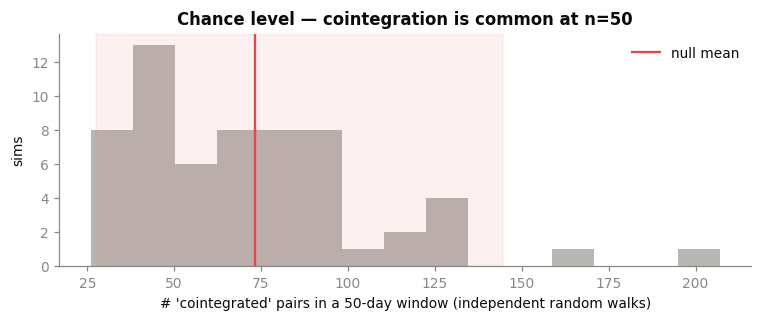

In [3]:
def matrix_null_counts(n_obs, n_inst, n_sims, thresh=0.05, seed=0):
    rng = np.random.default_rng(seed)
    counts = np.zeros(n_sims, dtype=int)
    for s in range(n_sims):
        walks = np.cumsum(rng.standard_normal((n_obs, n_inst)), axis=0)
        c = 0
        for i in range(n_inst):
            wi = walks[:, i]
            for j in range(i + 1, n_inst):
                if fast_coint(wi, walks[:, j]) < thresh:
                    c += 1
        counts[s] = c
    return counts

t0 = time.perf_counter()
null_counts = matrix_null_counts(W, N, n_sims=60)
n_possible = N * (N - 1) // 2
null_rate = null_counts.mean() / n_possible
null_lo, null_hi = np.percentile(null_counts, [2.5, 97.5])
print(f"Monte-Carlo ({len(null_counts)} sims, {time.perf_counter()-t0:.0f}s):")
print(f"  false-positive rate at n={W}: {null_rate:.1%}  (nominal 5%)")
print(f"  null count per window: mean {null_counts.mean():.0f} "
      f"of {n_possible}  |  95% band [{null_lo:.0f}, {null_hi:.0f}]")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(null_counts, bins=15, color=MUTED, alpha=0.6)
ax.axvspan(null_lo, null_hi, color=RED, alpha=0.08)
ax.axvline(null_counts.mean(), color=RED, lw=1.5, label="null mean")
ax.set_xlabel("# 'cointegrated' pairs in a 50-day window (independent random walks)")
ax.set_ylabel("sims"); ax.set_title("Chance level — cointegration is common at n=50")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## 3 · Cointegration matrix in every window

For each rolling window we compute the full `N×N` Engle–Granger p-value matrix
(one direction per unordered pair, mirrored). `Croll` is the boolean
"cointegrated at 5%" stack. This is the heavy cell.

In [4]:
def window_pmatrix(vals):
    '''vals: (W, N) price block -> symmetric NxN p-value matrix.'''
    n = vals.shape[1]
    P = np.full((n, n), np.nan)
    for i in range(n):
        yi = vals[:, i]
        for j in range(i + 1, n):
            p = fast_coint(yi, vals[:, j])
            P[i, j] = P[j, i] = p
    return P

t0 = time.perf_counter()
Proll = np.empty((len(starts), N, N))
for k, s in enumerate(starts):
    Proll[k] = window_pmatrix(prices.values[s:s + W])
Croll = Proll < 0.05                                   # boolean: cointegrated
print(f"Computed {len(starts)} window matrices in {time.perf_counter()-t0:.0f}s")

# non-overlapping blocks (independent) for the persistence statistics
Pblk = Proll[noov_pos]
Cblk = Croll[noov_pos]
n_blocks = len(noov_pos)
for k in range(len(starts)):
    np.fill_diagonal(Croll[k], False)
for k in range(n_blocks):
    np.fill_diagonal(Cblk[k], False)
print(f"{n_blocks} independent blocks retained for significance tests")

Computed 71 window matrices in 97s
15 independent blocks retained for significance tests


## 4 · Seriation — making the bands visible

A cointegration matrix in **ticker order** looks like noise. The bands only appear
once instruments that repeatedly cointegrate are placed next to each other. We
build the **persistence matrix** `F` (fraction of the 15 independent blocks in
which each pair is cointegrated), turn `1 − F` into a distance, run hierarchical
clustering, and use the leaf order for *every* heatmap below. `fcluster` then cuts
the tree into groups — the **candidate** bands.

> The trap: clustering *always* returns groups, even on pure noise. A drawn box is
> only a real band if the persistence values inside it are high — which we test in
> §6, not assume here.

In [5]:
F = Cblk.mean(axis=0)                                   # persistence: P(cointegrated) per pair
np.fill_diagonal(F, 1.0)

D = 1.0 - F
D = (D + D.T) / 2
np.fill_diagonal(D, 0.0)
Z = linkage(squareform(D, checks=False), method="average")
order = leaves_list(Z)
ORD_TICKERS = [TICKERS[i] for i in order]

# cut into a handful of clusters (candidate bands)
NCLUST = 8
labels = fcluster(Z, t=NCLUST, criterion="maxclust")
lab_ord = labels[order]
# cluster block boundaries along the ordered axis
bounds = [k for k in range(1, N) if lab_ord[k] != lab_ord[k - 1]]

# report clusters with >=2 members (singletons are not bands)
from collections import Counter
sizes = Counter(labels)
print(f"{NCLUST}-cluster cut; multi-member groups (candidate bands):")
for cl, sz in sorted(sizes.items(), key=lambda kv: -kv[1]):
    if sz >= 2:
        members = [TICKERS[i] for i in range(N) if labels[i] == cl]
        print(f"  cluster {cl:>2} (n={sz}): {', '.join(members)}")

8-cluster cut; multi-member groups (candidate bands):
  cluster  7 (n=16): DIHO, RTTH, RRES, SRTX, GARI, RCRI, MTNS, IHOZ, HRND, ULXY, BENI, ITPA, NGTE, FCSG, MHRM, EAFC
  cluster  8 (n=13): ALGO, AENO, SRNA, SMAH, EORC, HRET, AGVF, CTGI, CCNS, FWWG, EELT, BLBT, ILVX
  cluster  6 (n=10): HUXZ, ANSO, SPLZ, MDGI, ALUT, ACAC, ACIX, AETS, HTRK, FARS
  cluster  3 (n=4): ELLT, AMRP, NPCK, MMBT
  cluster  4 (n=3): DUCT, MSDP, CUBO
  cluster  1 (n=2): LSST, HETT
  cluster  2 (n=2): NWIG, NAYO


## 5 · The 15 windowed matrices side by side

Binary cointegration (blue = cointegrated at 5%) for each non-overlapping block,
all in the **same clustered order**, with cluster boundaries drawn. Watch the blue
blocks appear, move, and dissolve from block to block. The count in each title is
the pair count vs the chance mean from §2.

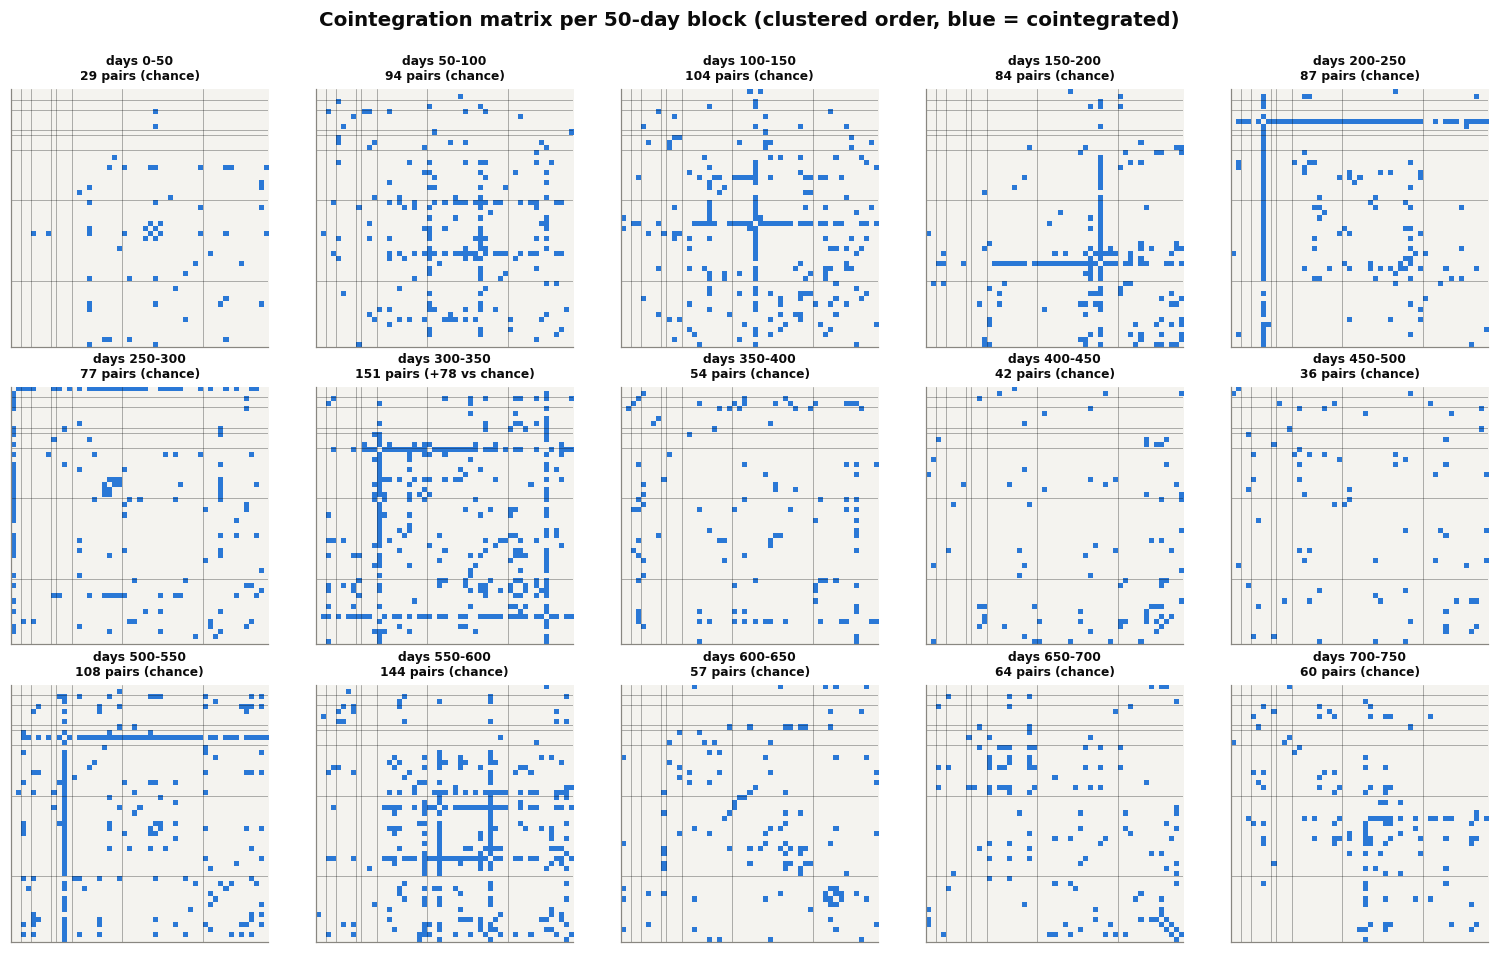

In [6]:
def draw_bounds(ax, bounds, n):
    for b in bounds:
        ax.axhline(b - 0.5, color=INK, lw=0.4, alpha=0.5)
        ax.axvline(b - 0.5, color=INK, lw=0.4, alpha=0.5)

nrow, ncol = 3, 5
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 8.6))
for k, ax in enumerate(axes.flat):
    if k >= n_blocks:
        ax.axis("off"); continue
    M = Cblk[k][np.ix_(order, order)].astype(float)
    ax.imshow(M, cmap=BIN, vmin=0, vmax=1, interpolation="nearest")
    draw_bounds(ax, bounds, N)
    cnt = int(Cblk[k].sum() // 2)
    s = starts[noov_pos[k]]
    excess = "chance" if cnt <= null_hi else f"+{cnt-int(null_counts.mean())} vs chance"
    ax.set_title(f"days {s}-{s+W}\n{cnt} pairs ({excess})", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Cointegration matrix per 50-day block (clustered order, blue = cointegrated)",
             fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout(); plt.show()

## 6 · The persistence map — which bands are real

Averaging over the 15 independent blocks cancels the noise: a pair cointegrated
purely by chance shows up in ~6% of blocks (§2), a **real** band would show up in
most. The matrix below is `F` (share of blocks cointegrated), clustered, with band
boundaries. **Watch the colour scale** — it is capped at the actual maximum, and
that maximum turns out to be only ~5 of 15 blocks. Faint blocks are the first sign
that stable 50-day bands may not really exist.

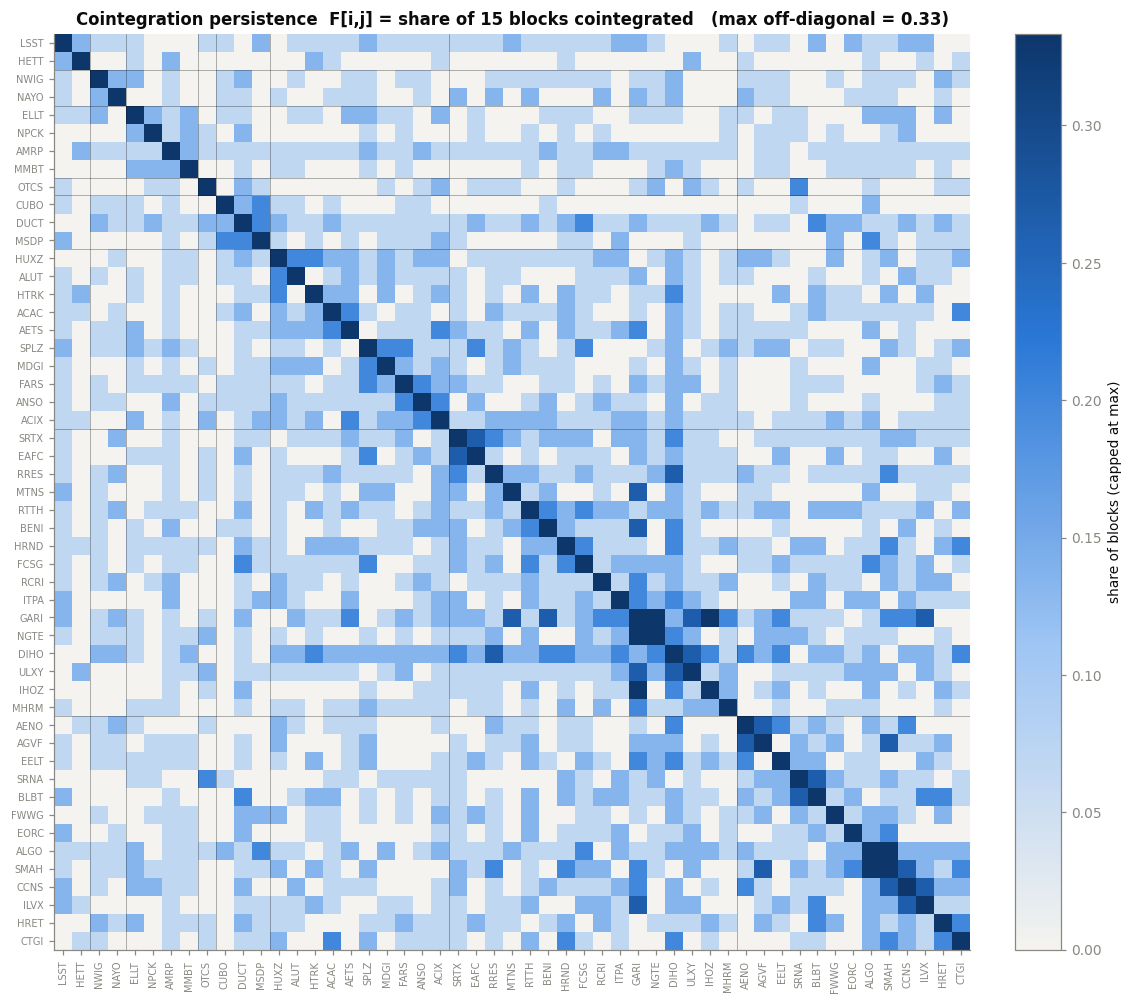

In [7]:
offdiag = F.copy(); np.fill_diagonal(offdiag, np.nan)
vmax = float(np.nanmax(offdiag))                        # honest cap = strongest real pair

fig, ax = plt.subplots(figsize=(11, 9.2))
im = ax.imshow(F[np.ix_(order, order)], cmap=SEQ, vmin=0, vmax=vmax,
               interpolation="nearest")
draw_bounds(ax, bounds, N)
ax.set_xticks(range(N)); ax.set_xticklabels(ORD_TICKERS, rotation=90, fontsize=6.5)
ax.set_yticks(range(N)); ax.set_yticklabels(ORD_TICKERS, fontsize=6.5)
ax.set_title(f"Cointegration persistence  F[i,j] = share of {n_blocks} blocks cointegrated"
             f"   (max off-diagonal = {vmax:.2f})")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="share of blocks (capped at max)")
fig.tight_layout(); plt.show()

### 5% chance vs persistence — the significance test

Under the null, the number of blocks a pair is cointegrated in is
`Binomial(15, r)` with `r` = the small-sample false-positive rate from §2. A pair
cointegrated in `k` of 15 blocks has significance `P(X ≥ k)`.

But we run this test on **all 1,275 pairs at once**, so ~13 pairs will look
significant at the 1% level by chance alone. The honest bar is **Bonferroni**
(1% / 1275 ≈ 8×10⁻⁶): how many pairs are persistent enough to survive testing the
whole matrix? We flag which of the survivors, if any, were focus pairs.

In [8]:
rows = []
for i in range(N):
    for j in range(i + 1, N):
        k = int(Cblk[:, i, j].sum())
        if k == 0:
            continue
        pval = binom.sf(k - 1, n_blocks, null_rate)
        rows.append({"pair": f"{TICKERS[i]}~{TICKERS[j]}",
                     "blocks_coint": k, "share": k / n_blocks,
                     "binom_p": pval,
                     "mean_p": np.nanmean(Pblk[:, i, j]),
                     "is_focus": (TICKERS[i], TICKERS[j]) in
                                 {tuple(p) for p in PAIRS} | {tuple(p[::-1]) for p in PAIRS}})
persist = pd.DataFrame(rows).sort_values(["blocks_coint", "binom_p"],
                                         ascending=[False, True]).reset_index(drop=True)
sig = persist[persist.binom_p < 0.01]
bonf = 0.01 / n_possible
exp_1pct = 0.01 * n_possible
print(f"Max blocks any pair is cointegrated in: {persist.blocks_coint.max()} of {n_blocks}")
print(f"Per single block, ~{null_rate*n_possible:.0f} of {n_possible} pairs fire by chance.")
print(f"Pairs 'significant' at 1%: {len(sig)}  "
      f"(but ~{exp_1pct:.0f} expected by chance across {n_possible} tests -> not distinguishable)")
print(f"Pairs surviving Bonferroni ({bonf:.1e}): {(persist.binom_p < bonf).sum()}")
print(f"Focus pairs appearing at least once: {persist.is_focus.sum()}/{len(PAIRS)}; "
      f"clearing the 1% bar: {sig.is_focus.sum()}")
persist.head(25).round(4)

Max blocks any pair is cointegrated in: 5 of 15
Per single block, ~73 of 1275 pairs fire by chance.
Pairs 'significant' at 1%: 15  (but ~13 expected by chance across 1275 tests -> not distinguishable)
Pairs surviving Bonferroni (7.8e-06): 0
Focus pairs appearing at least once: 12/13; clearing the 1% bar: 0


,pair,blocks_coint,share,binom_p,mean_p,is_focus
0,ALGO~SMAH,5,0.3333,0.0011,0.3055,False
1,GARI~IHOZ,5,0.3333,0.0011,0.3432,False
2,GARI~NGTE,5,0.3333,0.0011,0.2959,False
3,AENO~AGVF,4,0.2667,0.0089,0.4248,False
4,SRNA~BLBT,4,0.2667,0.0089,0.4588,False
5,SMAH~AGVF,4,0.2667,0.0089,0.2860,False
6,SMAH~CCNS,4,0.2667,0.0089,0.2514,False
7,DIHO~RRES,4,0.2667,0.0089,0.4611,False
8,DIHO~ULXY,4,0.2667,0.0089,0.4552,False
9,SRTX~EAFC,4,0.2667,0.0089,0.4748,False


## 7 · Instrument-level bands through time

For each rolling window, an instrument's **degree** = how many partners it
cointegrates with. Plotted as instrument (clustered rows) × time (window centre),
this is the clearest "band" view:

- a bright **horizontal band** = an instrument that is a persistent cointegration
  hub;
- a bright **vertical band** = a window where the *whole market* co-moves
  (everything cointegrates at once — a regime).

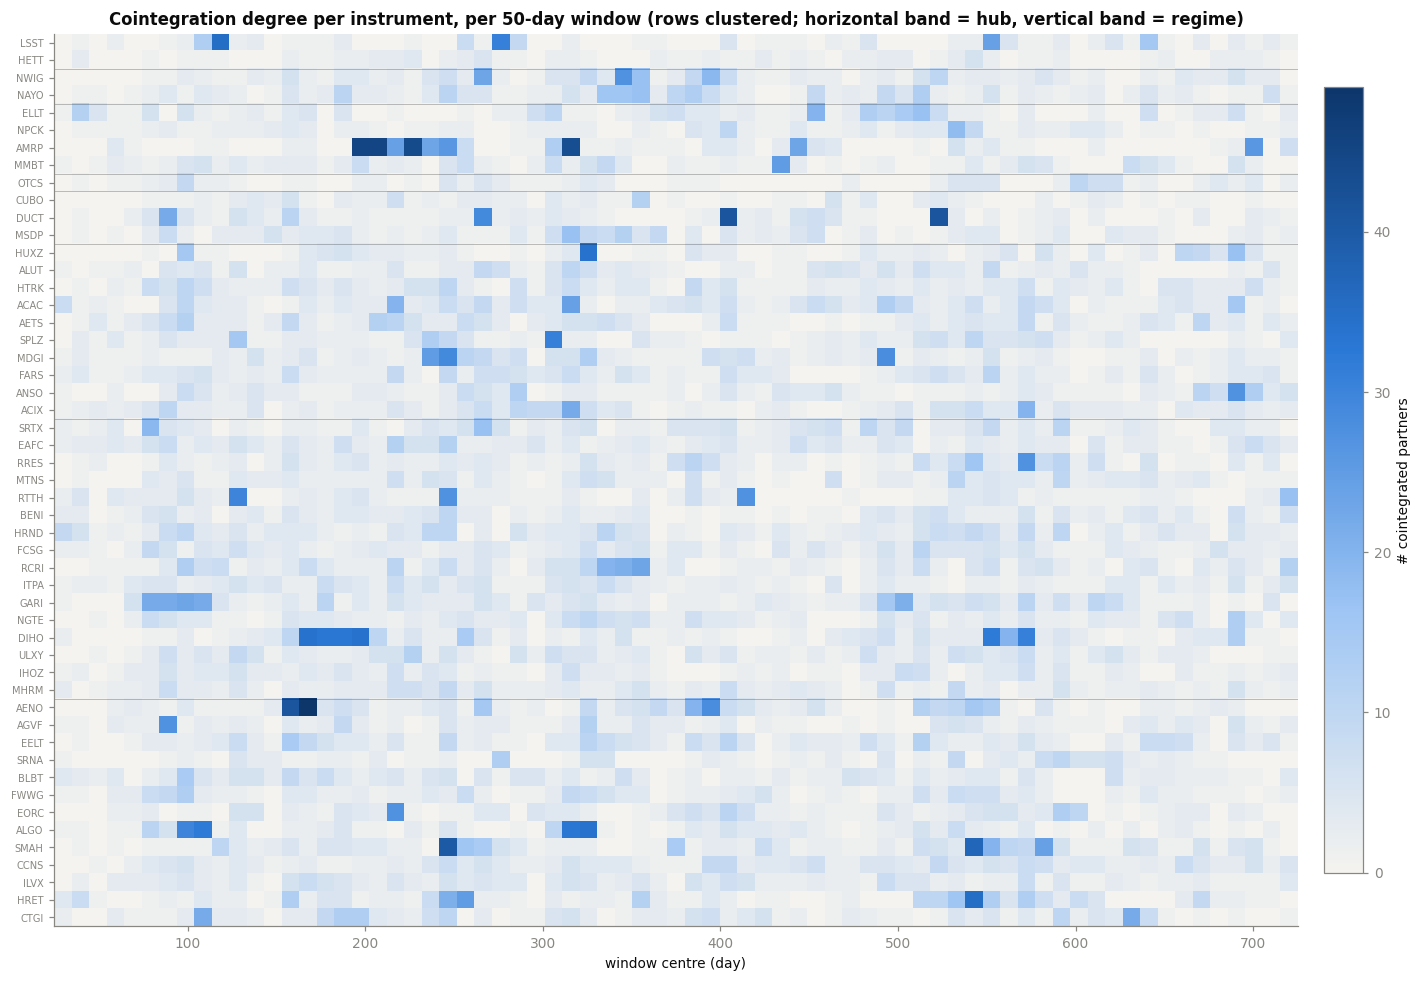

In [9]:
deg = Croll.sum(axis=2).T                              # (N instruments, W windows)
deg_ord = deg[order]

fig, ax = plt.subplots(figsize=(13, 9))
im = ax.imshow(deg_ord, aspect="auto", cmap=SEQ, interpolation="nearest",
               extent=[centers[0], centers[-1], N - 0.5, -0.5])
ax.set_yticks(range(N)); ax.set_yticklabels(ORD_TICKERS, fontsize=6.5)
for b in bounds:
    ax.axhline(b - 0.5, color=INK, lw=0.4, alpha=0.4)
ax.set_xlabel("window centre (day)")
ax.set_title("Cointegration degree per instrument, per 50-day window "
             "(rows clustered; horizontal band = hub, vertical band = regime)")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="# cointegrated partners")
fig.tight_layout(); plt.show()

## 8 · Market-wide regime — total cointegration through time

Total cointegrated-pair count in each rolling window, against the chance band from
§2. Excursions **above** the red band are windows with genuinely elevated
market-wide comovement; dips toward the band are "nothing but noise" regimes. This
is the moving pattern, quantified.

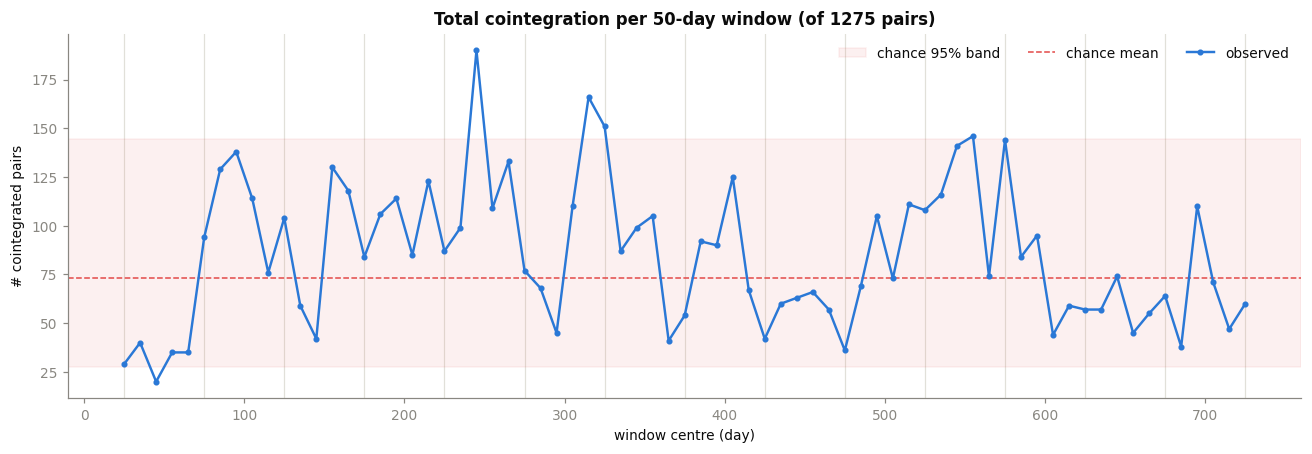

windows above chance band: 4 / 71
peak: 190 pairs at day ~245; trough: 20 pairs at day ~45


In [10]:
tot = Croll.sum(axis=(1, 2)) // 2                       # pairs per rolling window

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.axhspan(null_lo, null_hi, color=RED, alpha=0.08, label="chance 95% band")
ax.axhline(null_counts.mean(), color=RED, lw=1, ls="--", label="chance mean")
ax.plot(centers, tot, color=BLUE, lw=1.6, marker="o", ms=3, label="observed")
# shade non-overlapping block centres
for s in [starts[k] for k in noov_pos]:
    ax.axvline(s + W // 2, color=GRID, lw=0.8, zorder=0)
ax.set_xlabel("window centre (day)"); ax.set_ylabel("# cointegrated pairs")
ax.set_title(f"Total cointegration per 50-day window (of {n_possible} pairs)")
ax.legend(frameon=False, ncol=3); fig.tight_layout(); plt.show()

print(f"windows above chance band: {(tot > null_hi).sum()} / {len(tot)}")
print(f"peak: {tot.max()} pairs at day ~{centers[int(np.argmax(tot))]}; "
      f"trough: {tot.min()} pairs at day ~{centers[int(np.argmin(tot))]}")

## 9 · Do the focus pairs survive the windowing?

A pair can be strongly cointegrated over the full 750 days yet blink in and out
over 50-day windows. Here each focus pair is a row; colour is −log₁₀(p) per rolling
window (brighter = more cointegrated); the black dots mark windows where it clears
5%. Lots of gaps = a full-sample relationship that is **not** reliable at 50 days.

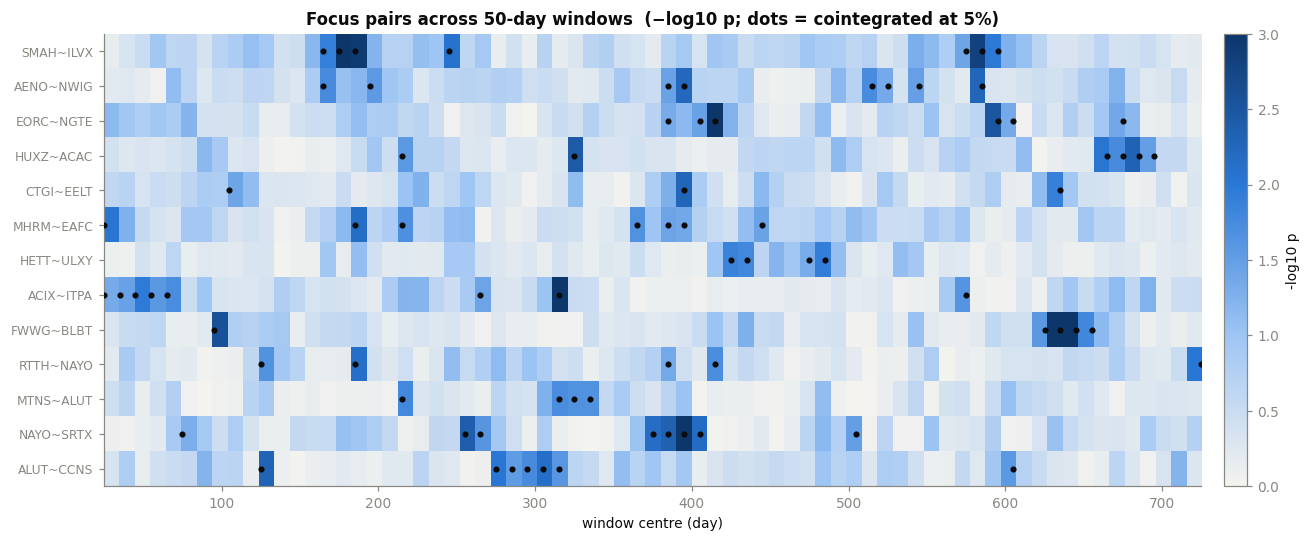

share of windows each focus pair is cointegrated at 5%:
  AENO~NWIG: 11%
  ACIX~ITPA: 11%
  NAYO~SRTX: 11%
  SMAH~ILVX: 10%
  MHRM~EAFC: 10%
  ALUT~CCNS: 10%
  EORC~NGTE: 8%
  HUXZ~ACAC: 8%
  FWWG~BLBT: 7%
  RTTH~NAYO: 7%
  HETT~ULXY: 6%
  MTNS~ALUT: 6%
  CTGI~EELT: 4%


: 

In [ ]:
fp = [(a, b) for a, b in PAIRS]
mat = np.zeros((len(fp), len(starts)))
hit = np.zeros_like(mat, dtype=bool)
for r, (a, b) in enumerate(fp):
    i, j = IDX[a], IDX[b]
    p = Proll[:, i, j]
    mat[r] = -np.log10(np.clip(p, 1e-4, 1))
    hit[r] = p < 0.05

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(mat, aspect="auto", cmap=SEQ, vmin=0, vmax=3, interpolation="nearest",
               extent=[centers[0], centers[-1], len(fp) - 0.5, -0.5])
yy, xx = np.where(hit)
ax.scatter(np.array(centers)[xx], yy, s=9, color=INK, zorder=3)
ax.set_yticks(range(len(fp))); ax.set_yticklabels([f"{a}~{b}" for a, b in fp], fontsize=8)
ax.set_xlabel("window centre (day)")
ax.set_title("Focus pairs across 50-day windows  (−log10 p; dots = cointegrated at 5%)")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="-log10 p")
fig.tight_layout(); plt.show()

frac_hit = hit.mean(axis=1)
print("share of windows each focus pair is cointegrated at 5%:")
for (a, b), f_ in sorted(zip(fp, frac_hit), key=lambda t: -t[1]):
    print(f"  {a}~{b}: {f_:.0%}")

## 10 · Analysis — what the bands actually are

The 50-day windowed matrices really do show shifting "pair bands" (§5) — but the
statistics say **most of that pattern is small-sample noise, with one genuine
exception: market-wide regime.**

**1. A single 50-day matrix is mostly false positives.** The Monte-Carlo on
*independent random walks* (§2) fires on ~6% of pairs at n = 50 — so ~73 of the
1,275 pairs "cointegrate" in an average window **purely by chance**. A band that is
bright in one window and gone the next is exactly what that noise looks like. Any
one window's matrix cannot be read pair-by-pair.

**2. No individual pair band survives the noise.** Persistence (§6) is the filter:
a chance pair should appear in ~1 of 15 independent blocks, a structural pair in
most. In this data the **strongest pair reaches only 5 of 15 blocks**, the
persistence matrix is faint, and after correcting for testing all 1,275 pairs
(**Bonferroni → 0 survivors**; 15 "significant" at 1% vs ~13 expected by chance)
**there is no evidence of a stable per-pair 50-day cointegration band.** The
clustered blocks in §4–6 are what hierarchical clustering *always* draws; their
contents reshuffle window to window.

**3. The one robust, moving pattern is market-wide regime (§7–8).** While *which*
pairs light up is noise, the *total* cointegration count is not: it swings from ~20
pairs (below the chance band — a trending, low-comovement regime) to a peak of ~190
(day ~245, well above the chance band's upper edge of ~145 — a broad
co-movement/stress episode). The bright **vertical bands** in the degree heatmap
are these regimes. This is the "pattern that moves through the windows" — an
aggregate comovement signal, not a set of tradeable pairs.

**4. Full-sample-cointegrated pairs are invisible at 50 days (§9).** The hand-
picked focus pairs are cointegrated in only ~4–11% of windows — at or below the
6% chance rate. Their half-lives (6–25 days, main notebook) mean a 50-day window
holds too few reversion cycles to reject the unit root. The *relationship* is real
over the long run; the 50-day *test* simply has no power to see it.

**Trading implications**
- **Do not mine 50-day cointegration matrices for pairs.** One-window (or even
  few-window) cointegration is indistinguishable from chance here — you would be
  trading noise. Select pairs on a **long look-back / full sample** (the main
  notebook), where power exists.
- **Use the windowed view for monitoring, not discovery.** The aggregate count vs
  the chance band (§8) is a genuine **regime indicator** — rising market-wide
  comovement is a signal to widen entry bands, cut gross exposure, or re-estimate
  hedge ratios, because relationships are being buffeted by a common shock.
- **Window length is a power knob, and 50 is short.** This notebook quantifies how
  short: at n = 50 the test can neither confirm real pairs nor rule out fake ones.
  Estimate spreads on ≥150–250 days; reserve short windows for the regime overlay.

> Caveats: p-values use `maxlag=1` for speed — the qualitative picture (chance
> level, absent persistence, real regimes) is robust to that choice, but re-run a
> shortlisted pair with the full AIC-lag test before trusting a number. And the
> regime read on the rolling count uses overlapping windows, so treat the *shape*
> (excursions beyond the band) as the signal, not each window as independent.